# Decision Tree: Hotel Booking Cancellations

Uses the **group cleaning from `Team Project.ipynb`** (Section 1a), plus a few extra steps the tree needs (Section 1b).

Random seed 888 everywhere, relative CSV path, runs top-to-bottom on a fresh kernel.

Running all cells also saves the 4 charts, `results_table.csv` and `leakage_check.csv` to this folder.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

SEED = 888
np.random.seed(SEED)

df_raw = pd.read_csv("HotelBookings.csv")
print(df_raw.shape)
print("Cancellation rate:", round(df_raw["is_canceled"].mean(), 3))

(69710, 30)
Cancellation rate: 0.273


## 1. Data preparation

**1a. Group cleaning**, copied from `Team Project.ipynb` in the same order. Two small fixes so it runs (marked `FIX` in the code):
- the `adr` 5400 cell had an extra space at the start of a line (IndentationError), so the outlier was never replaced
- filling missing `country` with "Unknown" failed because `country` was already a category type (TypeError)

**1b. Extra steps for the tree** (mine, not in the group notebook):

| Step | Why |
|---|---|
| Month, day of week and total nights taken from `arrival_date`, then `arrival_date` dropped | models need numbers, not dates |
| `arrival_date_week_number` dropped | highly correlated with month (profiling report) |
| `company` replaced with `has_company` yes/no flag | 94% missing |
| Top 15 countries and top 20 agents kept, rest grouped as "Other" | too many categories otherwise |
| `assigned_room_type` and `room_changed` dropped by default (toggle below) | both depend on the room given at check-in, so they may leak the outcome |
| Text columns one-hot encoded | sklearn trees only take numbers |

In [2]:
DROP_LEAKY = True   # set False to keep assigned_room_type and room_changed

def clean_data(df, median_adr=None):
    """Group cleaning from Team Project.ipynb (same steps, same order).
    median_adr: pass the training value when cleaning new data (Part 3)."""
    df = df.copy()

    categorical_cols = ['hotel','meal','country','market_segment','distribution_channel',
                        'reserved_room_type', 'assigned_room_type', 'deposit_type', 'agent',
                        'company', 'customer_type']
    df[categorical_cols] = df[categorical_cols].astype("category")

    df['arrival_date'] = pd.to_datetime(
        df['arrival_date_year'].astype(str) + '-' +
        df['arrival_date_month'] + '-' +
        df['arrival_date_day_of_month'].astype(str), format="%Y-%B-%d")
    df = df.drop(columns=['arrival_date_year', 'arrival_date_month', 'arrival_date_day_of_month'])

    df['room_changed'] = (df['reserved_room_type'].astype(str)
                          != df['assigned_room_type'].astype(str)).astype(int)
    df['children'] = df['children'].fillna(0)
    df['agent_booked'] = df['agent'].notna().astype(int)

    df['zero_night_zero_adr'] = ((df['stays_in_weekend_nights'] == 0) &
                                 (df['stays_in_week_nights'] == 0) &
                                 (df['adr'] == 0))

    # remove 46 rows with no guests, no nights and no revenue
    df = df[~((df['adults'] == 0) & (df['children'] == 0) & (df['babies'] == 0) &
              (df['stays_in_weekend_nights'] == 0) & (df['stays_in_week_nights'] == 0) &
              (df['adr'] == 0))]

    # FIX: removed the stray leading space that caused an IndentationError
    if median_adr is None:
        median_adr = df['adr'].median()
    df.loc[df['adr'] == 5400, 'adr'] = median_adr

    # FIX: add 'Unknown' as a category first, otherwise fillna raises a TypeError
    df['country'] = df['country'].cat.add_categories('Unknown').fillna('Unknown')
    df['country'] = df['country'].replace({'CN': 'CHN'})
    df['meal'] = df['meal'].replace({'Undefined': 'SC'})
    return df


def clean_data_median(df):
    """Median adr after the 46 empty rows are removed (matches the group cleaning)."""
    keep = ~((df['adults'] == 0) & (df['children'].fillna(0) == 0) & (df['babies'] == 0) &
             (df['stays_in_weekend_nights'] == 0) & (df['stays_in_week_nights'] == 0) &
             (df['adr'] == 0))
    return df.loc[keep, 'adr'].median()


def prepare_data(df, drop_leaky=DROP_LEAKY, ref=None):
    """Group cleaning, then the extra steps the tree needs.
    ref=None : learn median adr, top countries/agents and column list from df (training data).
    ref=dict : reuse values learned from training data (use for the Part 3 test file).
    Returns X, y, ref."""
    fit = ref is None
    if fit:
        ref = {"median_adr": clean_data_median(df)}
    d = clean_data(df, median_adr=ref["median_adr"])

    d['arrival_month'] = d['arrival_date'].dt.month
    d['arrival_dayofweek'] = d['arrival_date'].dt.dayofweek
    d['total_nights'] = d['stays_in_weekend_nights'] + d['stays_in_week_nights']
    d = d.drop(columns=['arrival_date', 'arrival_date_week_number'])
    d['zero_night_zero_adr'] = d['zero_night_zero_adr'].astype(int)

    d['has_company'] = d['company'].notna().astype(int)
    d = d.drop(columns=['company'])

    d['country'] = d['country'].astype(str)
    if fit:
        ref['top_countries'] = d['country'].value_counts().index[:15]
    top_countries = ref['top_countries']
    d['country'] = d['country'].where(d['country'].isin(top_countries), 'Other')

    d['agent'] = d['agent'].astype(float).fillna(0).astype(int).astype(str)
    if fit:
        ref['top_agents'] = d['agent'].value_counts().index[:20]
    top_agents = ref['top_agents']
    d['agent'] = d['agent'].where(d['agent'].isin(top_agents), 'Other')

    if drop_leaky:
        d = d.drop(columns=['assigned_room_type', 'room_changed'])

    cat_cols = d.select_dtypes(include=['object', 'string', 'category']).columns.tolist()
    d = pd.get_dummies(d, columns=cat_cols, dtype=int)

    y = d['is_canceled'] if 'is_canceled' in d else None
    X = d.drop(columns=['is_canceled'], errors='ignore')
    if fit:
        ref['columns'] = X.columns
    else:
        # categories missing from new data become 0 columns, unseen ones are dropped
        X = X.reindex(columns=ref['columns'], fill_value=0)
    return X, y, ref

X, y, ref = prepare_data(df_raw)
print("Rows after cleaning:", len(X), "| Features after encoding:", X.shape[1])
print("Any missing left:", X.isna().any().any())

Rows after cleaning: 69664 | Features after encoding: 93
Any missing left: False


/var/folders/5h/x42n2c6j2fv68qy7nzbn_8d40000gn/T/ipykernel_26410/4109453266.py:40: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  df['country'] = df['country'].replace({'CN': 'CHN'})
/var/folders/5h/x42n2c6j2fv68qy7nzbn_8d40000gn/T/ipykernel_26410/4109453266.py:41: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  df['meal'] = df['meal'].replace({'Undefined': 'SC'})


## 2. Train / validation split

Stratified so both sets keep the ~27% cancellation rate. **All models in the group should use this same split** so the comparison is fair.

In [3]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", X_train.shape, "cancel rate", round(y_train.mean(), 3))
print("Val:  ", X_val.shape, "cancel rate", round(y_val.mean(), 3))

Train: (55731, 93) cancel rate 0.273
Val:   (13933, 93) cancel rate 0.273


## 3. Evaluation helper

Accuracy alone is misleading here: predicting "no cancellation" for everyone already scores ~73%.
So we report precision, recall, F1 and ROC-AUC too. **The group should agree on one main metric.**

In [4]:
results = []

def evaluate(name, model):
    pred_tr = model.predict(X_train)
    pred = model.predict(X_val)
    proba = model.predict_proba(X_val)[:, 1]
    row = {
        "model": name,
        "train_f1": f1_score(y_train, pred_tr),
        "val_accuracy": accuracy_score(y_val, pred),
        "val_precision": precision_score(y_val, pred),
        "val_recall": recall_score(y_val, pred),
        "val_f1": f1_score(y_val, pred),
        "val_roc_auc": roc_auc_score(y_val, proba),
    }
    results.append(row)
    return pd.Series(row)

baseline_acc = 1 - y_val.mean()
print(f"Naive baseline (always predict 'not cancelled') accuracy: {baseline_acc:.3f}")

Naive baseline (always predict 'not cancelled') accuracy: 0.727


## 4. Unrestricted tree: shows overfitting

A tree with no limits memorises the training data. The gap between train and validation F1 is the evidence for tuning.

In [5]:
tree_full = DecisionTreeClassifier(random_state=SEED)
tree_full.fit(X_train, y_train)
print("Depth:", tree_full.get_depth(), "| Leaves:", tree_full.get_n_leaves())
evaluate("Unrestricted tree", tree_full)

Depth: 57 | Leaves: 8547


model            Unrestricted tree
train_f1                  0.996138
val_accuracy              0.788847
val_precision             0.612038
val_recall                0.617833
val_f1                    0.614921
val_roc_auc               0.736084
dtype: object

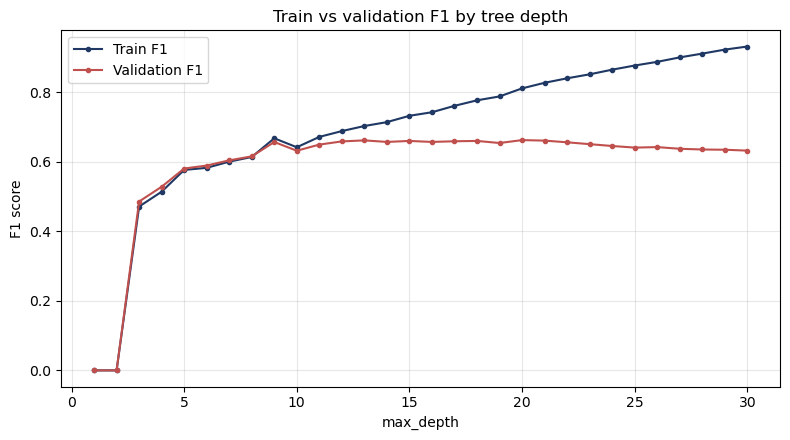

In [6]:
depths = range(1, 31)
train_scores, val_scores = [], []
for dep in depths:
    m = DecisionTreeClassifier(max_depth=dep, random_state=SEED).fit(X_train, y_train)
    train_scores.append(f1_score(y_train, m.predict(X_train)))
    val_scores.append(f1_score(y_val, m.predict(X_val)))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(depths, train_scores, marker="o", ms=3, label="Train F1", color="#1f3864")
ax.plot(depths, val_scores, marker="o", ms=3, label="Validation F1", color="#c0504d")
ax.set_xlabel("max_depth")
ax.set_ylabel("F1 score")
ax.set_title("Train vs validation F1 by tree depth")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
fig.savefig("1_depth_chart.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Tuning with cross-validation

Grid search over depth, minimum leaf size, split criterion and class weighting, with 5-fold stratified CV on the training set only.
Scoring on F1 as a placeholder, change `SCORING` if the group picks another metric.

In [7]:
SCORING = "f1"

param_grid = {
    "max_depth": [4, 6, 8, 10, 12, 15, None],
    "min_samples_leaf": [1, 5, 20, 50, 100],
    "criterion": ["gini", "entropy"],
    "class_weight": [None, "balanced"],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
grid = GridSearchCV(DecisionTreeClassifier(random_state=SEED), param_grid,
                    scoring=SCORING, cv=cv, n_jobs=-1)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print(f"Best CV {SCORING}: {grid.best_score_:.3f}")
best_tree = grid.best_estimator_
print("Leaves:", best_tree.get_n_leaves(), "| Depth:", best_tree.get_depth())
evaluate("Tuned tree", best_tree)

Best params: {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 15, 'min_samples_leaf': 1}
Best CV f1: 0.672
Leaves: 1286 | Depth: 15


model            Tuned tree
train_f1           0.721522
val_accuracy       0.774133
val_precision      0.557709
val_recall         0.832457
val_f1             0.667933
val_roc_auc        0.865205
dtype: object

## 6. Results comparison

In [8]:
results_df = pd.DataFrame(results).set_index("model").round(3)
results_df.to_csv("results_table.csv")
results_df

,train_f1,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc
model,,,,,,
Unrestricted tree,0.996,0.789,0.612,0.618,0.615,0.736
Tuned tree,0.722,0.774,0.558,0.832,0.668,0.865


               precision    recall  f1-score   support

Not cancelled       0.92      0.75      0.83     10131
    Cancelled       0.56      0.83      0.67      3802

     accuracy                           0.77     13933
    macro avg       0.74      0.79      0.75     13933
 weighted avg       0.82      0.77      0.78     13933



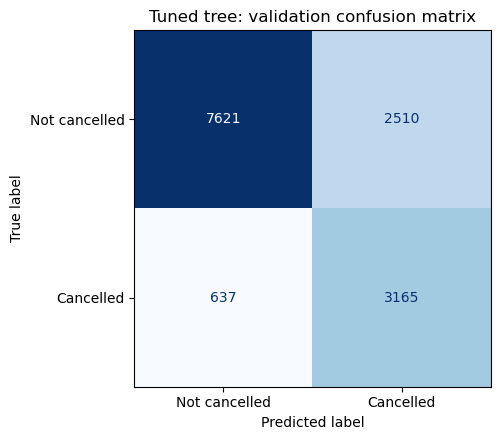

In [9]:
pred = best_tree.predict(X_val)
print(classification_report(y_val, pred, target_names=["Not cancelled", "Cancelled"]))

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_val, pred),
                       display_labels=["Not cancelled", "Cancelled"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Tuned tree: validation confusion matrix")
plt.tight_layout()
fig.savefig("2_confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Interpretation

This is the tree's main strength for the hotel: the rules can be read in plain English.

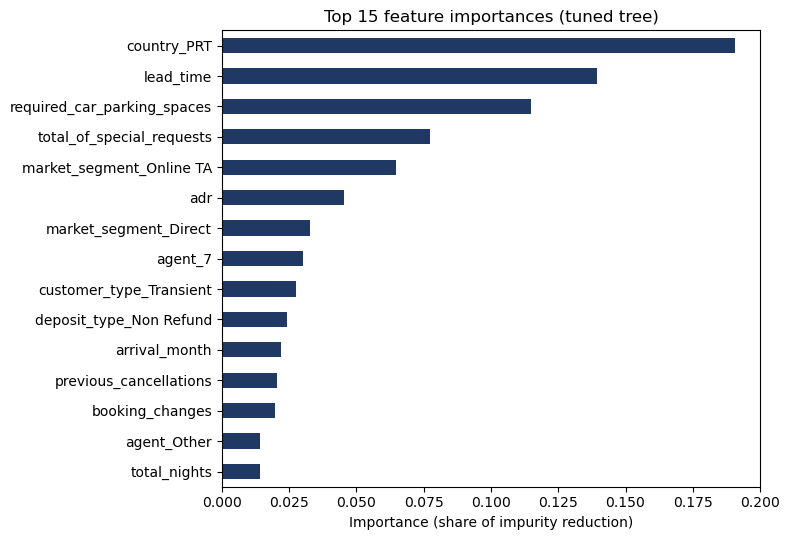

country_PRT                    0.191
lead_time                      0.139
required_car_parking_spaces    0.115
total_of_special_requests      0.078
market_segment_Online TA       0.065
adr                            0.045
market_segment_Direct          0.033
agent_7                        0.030
customer_type_Transient        0.027
deposit_type_Non Refund        0.024
arrival_month                  0.022
previous_cancellations         0.021
booking_changes                0.020
agent_Other                    0.014
total_nights                   0.014
dtype: float64

In [10]:
imp = pd.Series(best_tree.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 5.5))
imp[::-1].plot.barh(ax=ax, color="#1f3864")
ax.set_title("Top 15 feature importances (tuned tree)")
ax.set_xlabel("Importance (share of impurity reduction)")
plt.tight_layout()
fig.savefig("3_feature_importance.png", dpi=200, bbox_inches="tight")
plt.show()
imp.round(3)

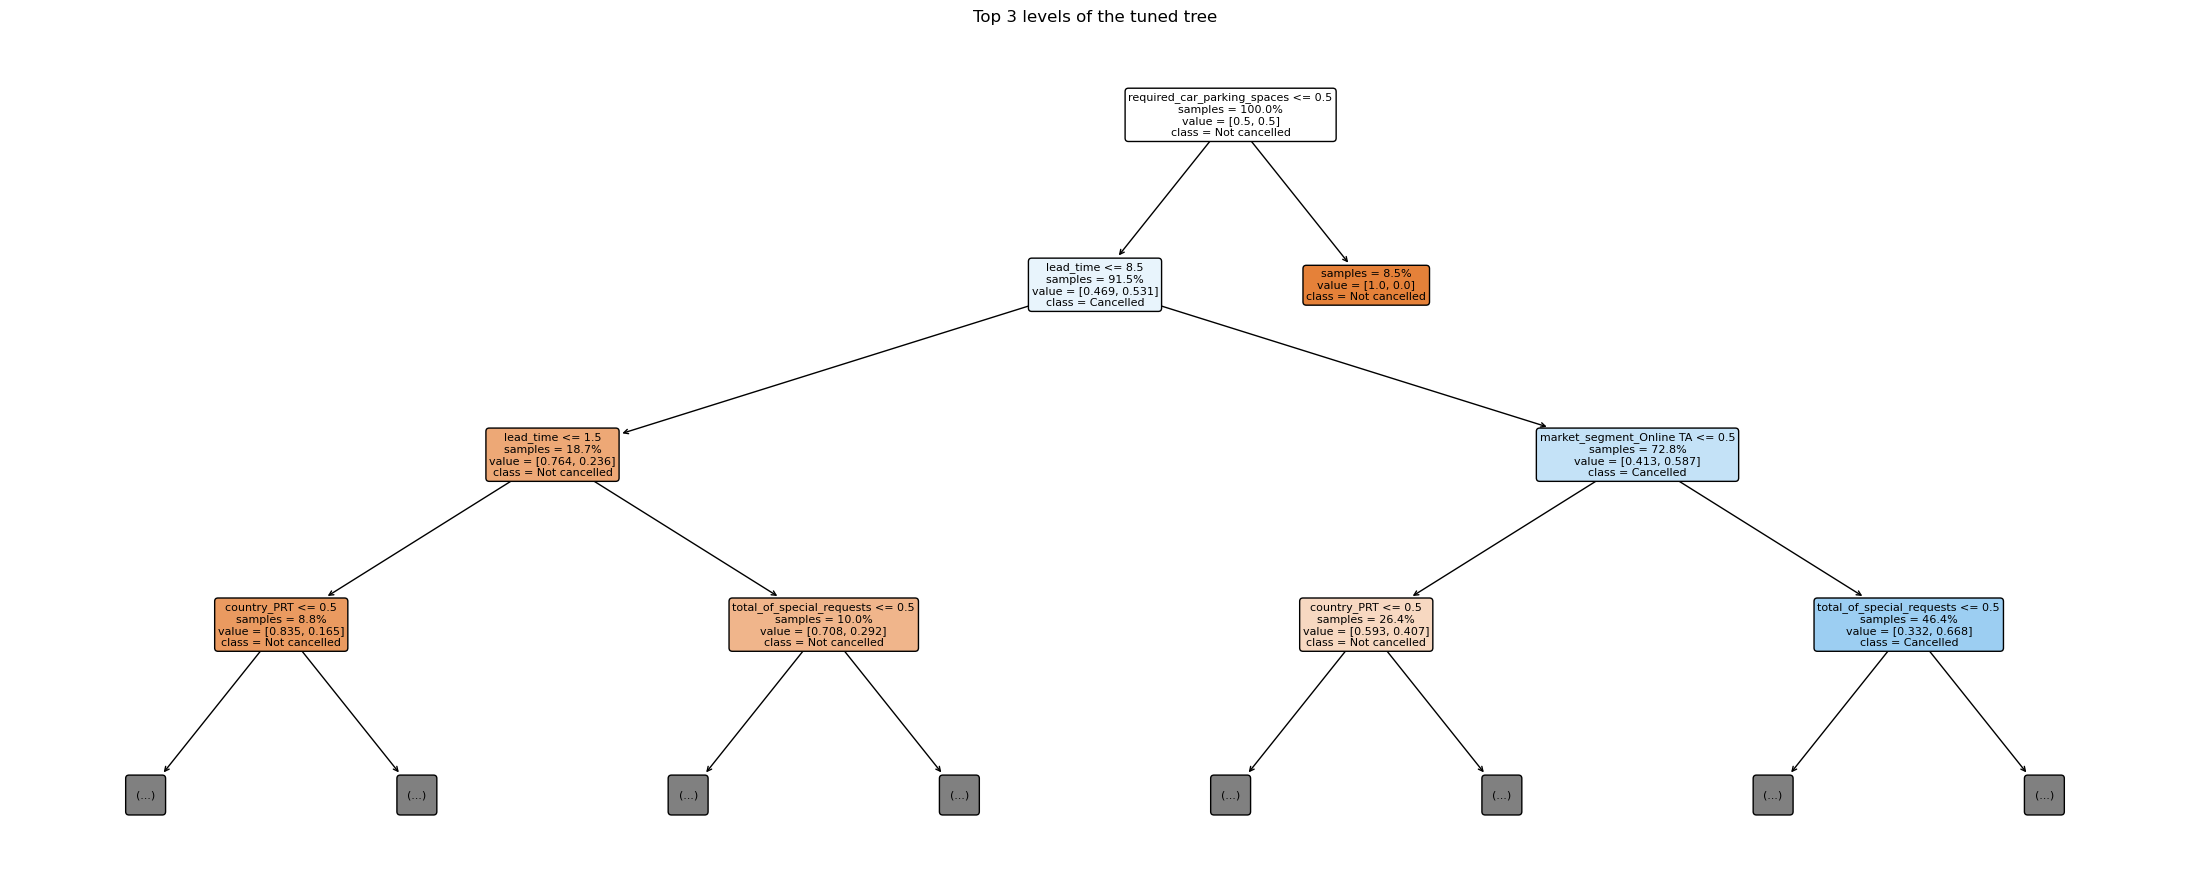

In [11]:
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(best_tree, max_depth=3, feature_names=X.columns,
          class_names=["Not cancelled", "Cancelled"], filled=True, rounded=True,
          fontsize=8, impurity=False, proportion=True, ax=ax)
ax.set_title("Top 3 levels of the tuned tree")
plt.tight_layout()
fig.savefig("4_tree_top3_levels.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Leakage check

Same split, same tuned settings as above; only the features change. Compares:
- **Baseline**: the tuned tree above (`assigned_room_type` and `room_changed` dropped)
- **With room features**: puts `assigned_room_type` and `room_changed` back in
- **Without parking**: baseline minus `required_car_parking_spaces` (0% of bookings with parking cancel, so it may only be recorded on arrival)

If a feature only exists after the guest arrives, the model would not have it when predicting, and its score gain is not real.

In [12]:
best_params = best_tree.get_params()
X_leaky, _, _ = prepare_data(df_raw, drop_leaky=False)   # same rows and order as X

variants = {
    "Baseline (tuned tree)":  (X_train.columns, X),
    "With room features":     (X_leaky.columns, X_leaky),
    "Without parking":        (X_train.columns.drop("required_car_parking_spaces"), X),
}

rows = []
for name, (cols, data) in variants.items():
    Xtr, Xv = data.loc[X_train.index, cols], data.loc[X_val.index, cols]
    m = DecisionTreeClassifier(**best_params).fit(Xtr, y_train)
    pred, proba = m.predict(Xv), m.predict_proba(Xv)[:, 1]
    rows.append({"variant": name,
                 "val_accuracy": accuracy_score(y_val, pred),
                 "val_precision": precision_score(y_val, pred),
                 "val_recall": recall_score(y_val, pred),
                 "val_f1": f1_score(y_val, pred),
                 "val_roc_auc": roc_auc_score(y_val, proba)})

leakage_df = pd.DataFrame(rows).set_index("variant").round(3)
leakage_df.to_csv("leakage_check.csv")
leakage_df

/var/folders/5h/x42n2c6j2fv68qy7nzbn_8d40000gn/T/ipykernel_26410/4109453266.py:40: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  df['country'] = df['country'].replace({'CN': 'CHN'})
/var/folders/5h/x42n2c6j2fv68qy7nzbn_8d40000gn/T/ipykernel_26410/4109453266.py:41: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  df['meal'] = df['meal'].replace({'Undefined': 'SC'})


,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc
variant,,,,,
Baseline (tuned tree),0.774,0.558,0.832,0.668,0.865
With room features,0.775,0.557,0.861,0.677,0.873
Without parking,0.758,0.539,0.800,0.644,0.839


In [13]:
# Cancellation rates behind the two suspect features
print(pd.crosstab(X_leaky['room_changed'], y, normalize='index').round(3))
print(pd.crosstab(X['required_car_parking_spaces'] > 0, y, normalize='index').round(3))

is_canceled       0      1
room_changed              
0             0.687  0.313
1             0.955  0.045
is_canceled                      0      1
required_car_parking_spaces              
False                        0.702  0.298
True                         1.000  0.000


## 9. Notes for the group

- **Group notebook fixes needed:** two cells in `Team Project.ipynb` error when run (see Section 1a).
- **Leakage check:** Section 8 runs all variants automatically. Group to decide on parking, and apply the same choice to every model.
- **Part 3 (held-out test):** reuse the values learned from the training data, so the test file is prepared exactly the same way:
  ```python
  df_test = pd.read_csv("HotelBookings_Test.csv")
  X_test, _, _ = prepare_data(df_test, ref=ref)   # ref = from training, NOT refit on test
  best_tree.predict(X_test)
  ```
  No retraining. `prepare_data` already lines up the columns.